# Cluster worksheet: Python exercises

Companion to `cluster_worksheet.pdf`. Each section matches a **[Py]** problem. Do the pen-and-paper part first, then
fill in the `TODO`s. The checks at the end of each section tell you whether your answer is in the expected range.
Everything uses toy data and runs in a few seconds (numpy, scipy, matplotlib; the `kl-nn` environment works).

In [1]:
import numpy as np
from scipy.stats import norm
import matplotlib.pyplot as plt
rng = np.random.default_rng(0)
BOX = 0.1   # training prior: uniform on |g| < 0.1

## A5. Why one galaxy's posterior mean is shrunk

Posterior = Gaussian likelihood (centre `d`, width `sigma`) truncated to `|x| < BOX`. Its mean is (A5a)
`d + sigma * (phi(alpha) - phi(beta)) / (Phi(beta) - Phi(alpha))`, with `alpha = (-BOX - d)/sigma` and
`beta = (BOX - d)/sigma`.

In [2]:
def posterior_mean(d, sigma):
    """Mean of N(d, sigma^2) truncated to [-BOX, BOX]."""
    a, b = (-BOX - d) / sigma, (BOX - d) / sigma
    return d + sigma * (norm.pdf(a) - norm.pdf(b)) / (norm.cdf(b) - norm.cdf(a))


def response(sigma, n_noise=20000):
    """Average the posterior mean over the noise d ~ N(x_true, sigma^2) for x_true in [-0.05, 0.05];
    fit E[mean] = (1 + m) x_true + c and return (m, c)."""
    x_true = np.linspace(-0.05, 0.05, 21)
    z = norm.ppf((np.arange(n_noise) + 0.5) / n_noise)
    mean = [posterior_mean(x + sigma * z, sigma).mean() for x in x_true]
    slope, c = np.polyfit(x_true, mean, 1)
    return slope - 1, c

In [3]:
# A5(c)-(d): one galaxy, then the product of N likelihoods (width sigma / sqrt(N))
for N in (1, 2, 4, 8, 16):
    m, c = response(0.07 / np.sqrt(N))
    print(f"N = {N:2d}: m = {m:+.4f}, c = {c:+.1e}")
assert abs(response(0.07)[0] + 0.57) < 0.02, "single-galaxy m should be about -0.57"

N =  1: m = -0.5719, c = +6.8e-19
N =  2: m = -0.3646, c = -5.7e-19
N =  4: m = -0.1712, c = +4.3e-19
N =  8: m = -0.0518, c = +1.2e-18


N = 16: m = -0.0085, c = -4.1e-19


## B5. The tangential frame, and checking a stack with pulls

A cell of 5 galaxies around a lens at the origin. Galaxy `i` sits at angle `phi_i`, has true tangential shear
`gt_i` (0.01 to 0.03), so its image-frame shear is `g = -gt * exp(2 i phi)` (B5b), and its likelihood has an
anisotropic covariance (sd 0.03 along a random direction, 0.07 across it).

In [4]:
n_gal = 5
phi = rng.uniform(-np.pi, np.pi, n_gal)
gt = np.linspace(0.01, 0.03, n_gal)
g_true = np.stack([-gt * np.cos(2 * phi), -gt * np.sin(2 * phi)], 1)      # image frame
covs = []
for _ in range(n_gal):
    a = rng.uniform(0, np.pi); u = np.array([np.cos(a), np.sin(a)]); v = np.array([-u[1], u[0]])
    covs.append(0.03**2 * np.outer(u, u) + 0.07**2 * np.outer(v, v))
covs = np.array(covs); F = np.linalg.inv(covs)

In [5]:
def R(p):
    """Image frame (g1, g2) -> (g_t, g_x) at position angle p."""
    c, s = np.cos(2 * p), np.sin(2 * p)
    return -np.array([[c, s], [-s, c]])

Rs = np.array([R(p) for p in phi])
Fp = np.einsum("iab,ibc,idc->iad", Rs, F, Rs)            # R F R^T
t = np.einsum("iab,ib->ia", Rs, g_true)
Ftot = Fp.sum(0); cov_G = np.linalg.inv(Ftot)
g_ref = cov_G @ np.einsum("iab,ib->a", Fp, t)
plain = t.mean(0)

pulls_ref, pulls_plain = [], []
for _ in range(2000):
    d = np.array([rng.multivariate_normal(g_true[i], covs[i]) for i in range(n_gal)])
    G = cov_G @ np.einsum("iab,ib->a", Fp, np.einsum("iab,ib->ia", Rs, d))
    pulls_ref.append((G - g_ref) / np.sqrt(np.diag(cov_G)))
    pulls_plain.append((G - plain) / np.sqrt(np.diag(cov_G)))
pulls_ref, pulls_plain = np.array(pulls_ref), np.array(pulls_plain)

In [6]:
print("g_ref (g_t, g_x) =", np.round(g_ref, 4), "  plain mean =", np.round(plain, 4))
print("pulls about g_ref : mean", np.round(pulls_ref.mean(0), 3), " sd", np.round(pulls_ref.std(0), 3))
print("pulls about plain : mean", np.round(pulls_plain.mean(0), 3), " sd", np.round(pulls_plain.std(0), 3))
assert np.all(np.abs(pulls_ref.mean(0)) < 0.1) and np.all(np.abs(pulls_ref.std(0) - 1) < 0.1)

g_ref (g_t, g_x) = [ 0.0205 -0.0013]   plain mean = [0.02 0.  ]
pulls about g_ref : mean [ 0.032 -0.004]  sd [1.004 0.99 ]
pulls about plain : mean [ 0.051 -0.097]  sd [1.004 0.99 ]


## D4. What binning does to a tangential pattern

An SIS-like subhalo with `g_t = A / r`, `A = 0.009` Mpc (C5). Cells are `DELTA = 0.98` Mpc squares. Average the
subhalo's image-frame shear over a cell whose centre is offset by `dx` from the subhalo, and compare with the shear at
the cell centre.

In [7]:
A, DELTA = 0.009, 0.98

def shear(x, y):
    r = np.hypot(x, y); p = np.arctan2(y, x)
    return -A / r * np.cos(2 * p), -A / r * np.sin(2 * p)

In [8]:
def cell_average(dx, n=400):
    """Average (g1, g2) over a DELTA x DELTA cell centred at (dx, 0), on an n x n grid of points."""
    u = (np.arange(n) + 0.5) / n - 0.5                     # never exactly 0, for even n
    X, Y = np.meshgrid(dx + DELTA * u, DELTA * u)
    g1, g2 = shear(X, Y)
    return g1.mean(), g2.mean()

for dx in (0.0, 0.25, 0.5, 0.75, 1.0):
    avg = np.hypot(*cell_average(dx))
    centre = np.hypot(*shear(dx, 0.0)) if dx > 0 else np.nan
    print(f"offset {dx:4.2f} Mpc: |cell average| = {avg:.5f}   |shear at centre| = {centre:.5f}")

print("smoothing factor at Nyquist:", np.exp(-(np.pi * 0.7) ** 2 / 2))

offset 0.00 Mpc: |cell average| = 0.00000   |shear at centre| = nan
offset 0.25 Mpc: |cell average| = 0.00016   |shear at centre| = 0.03600
offset 0.50 Mpc: |cell average| = 0.00517   |shear at centre| = 0.01800
offset 0.75 Mpc: |cell average| = 0.00838   |shear at centre| = 0.01200
offset 1.00 Mpc: |cell average| = 0.00759   |shear at centre| = 0.00900
smoothing factor at Nyquist: 0.08909490952726896


## E5. A one-dimensional Wiener filter

A toy 1D field on 60 pixels over 6 "Mpc": a broad bump (main halo) plus a narrow bump (subhalo). 200 galaxies at
random positions each measure the value of the pixel they fall in, with noise 0.05. The MAP map is
`H^-1 A^T N^-1 d` with `H = A^T N^-1 A + P`, where `P` is the prior precision of E4:
`P = (I + ell^2 D^T D) / sigma_k^2`, with `D` the neighbour-difference matrix.

In [9]:
M, LENGTH, NGAL, SIG = 60, 6.0, 200, 0.05
x_pix = (np.arange(M) + 0.5) * LENGTH / M
main = 0.05 * np.exp(-0.5 * ((x_pix - 2.0) / 1.2) ** 2)
bump = 0.03 * np.exp(-0.5 * ((x_pix - 4.0) / 0.25) ** 2)
D = np.diff(np.eye(M), axis=0)                           # (M-1) x M neighbour differences

def draw(n_gal=NGAL, rng=rng):
    """Galaxy pixel indices and unit noise for one realization."""
    return rng.integers(0, M, n_gal), rng.standard_normal(n_gal)

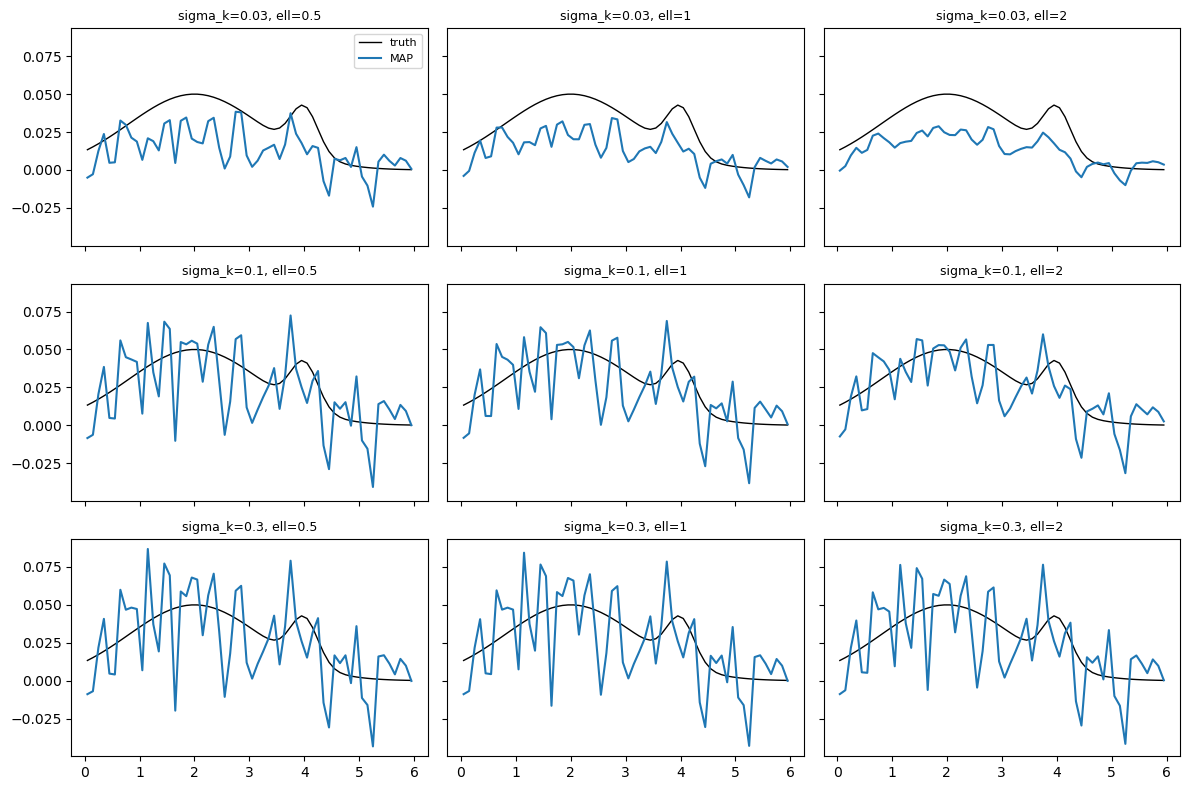

In [10]:
def design(idx):
    """A: each galaxy samples the pixel it falls in."""
    A = np.zeros((len(idx), M)); A[np.arange(len(idx)), idx] = 1.0
    return A

def map_estimate(idx, d, sigma_k, ell):
    """MAP map (E2) with the prior precision of E4."""
    A = design(idx)
    P = (np.eye(M) + ell ** 2 * D.T @ D) / sigma_k ** 2
    H = A.T @ A / SIG ** 2 + P
    return np.linalg.solve(H, A.T @ d / SIG ** 2)

idx, noise = draw()
truth = main + bump
d = truth[idx] + SIG * noise
fig, axes = plt.subplots(3, 3, figsize=(12, 8), sharex=True, sharey=True)
for i, sk in enumerate((0.03, 0.1, 0.3)):
    for j, ell in enumerate((0.5, 1, 2)):
        ax = axes[i, j]
        ax.plot(x_pix, truth, "k", lw=1, label="truth")
        ax.plot(x_pix, map_estimate(idx, d, sk, ell), "C0", label="MAP")
        ax.set_title(f"sigma_k={sk}, ell={ell}", fontsize=9)
axes[0, 0].legend(fontsize=8); plt.tight_layout()

peak of narrow bump: truth 0.041, mean map 0.022


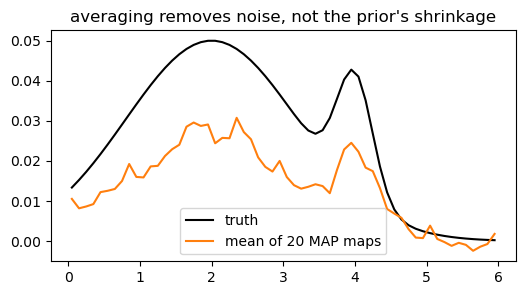

In [11]:
# E5(c): the mean over 20 noise realizations is NOT the truth
sk, ell = 0.03, 1.0
maps = []
for _ in range(20):
    i_, n_ = draw()
    maps.append(map_estimate(i_, truth[i_] + SIG * n_, sk, ell))
plt.figure(figsize=(6, 3))
plt.plot(x_pix, truth, "k", label="truth"); plt.plot(x_pix, np.mean(maps, 0), "C1", label="mean of 20 MAP maps")
plt.legend(); plt.title("averaging removes noise, not the prior's shrinkage")
print("peak of narrow bump: truth %.3f, mean map %.3f" % (truth[40], np.mean(maps, 0)[40]))

## F4. How many numbers do the data determine?

The resolution matrix is `R = H^-1 H_d`, with `H_d = A^T N^-1 A`. Its trace is the effective number of
well-determined parameters (F4a). Keep the physical smoothing length fixed (1 "Mpc pixel" at M = 60, i.e.
`ell_pix = M / 60`) and vary the number of pixels.

In [12]:
def trace_R(n_pix, idx_pos, sigma_k=0.03, ell_phys=0.1):
    """tr(H^-1 H_d) for n_pix pixels over LENGTH; galaxies at positions idx_pos (in [0, LENGTH))."""
    idx = np.minimum((idx_pos / LENGTH * n_pix).astype(int), n_pix - 1)
    A = np.zeros((len(idx), n_pix)); A[np.arange(len(idx)), idx] = 1.0
    Dn = np.diff(np.eye(n_pix), axis=0)
    ell_pix = ell_phys * n_pix / LENGTH
    Hd = A.T @ A / SIG ** 2
    H = Hd + (np.eye(n_pix) + ell_pix ** 2 * Dn.T @ Dn) / sigma_k ** 2
    return np.trace(np.linalg.solve(H, Hd))

pos = rng.uniform(0, LENGTH, NGAL)
for n_pix in (15, 30, 60, 120, 240):
    print(f"{n_pix:4d} pixels: tr R = {trace_R(n_pix, pos):.1f}")

  15 pixels: tr R = 12.1
  30 pixels: tr R = 18.3
  60 pixels: tr R = 19.0
 120 pixels: tr R = 13.1
 240 pixels: tr R = 7.7


## G4. The significance one map can claim

50 realizations, each with new galaxy positions and noise. For each, make the map with and without the narrow bump
(same galaxies, same noise), take the aperture average `a` over |x - 4| < 0.25, and compute
`z_r = (a_sub_r - mean(a_main)) / sd(a_main)` (G4). Use `sigma_k = 0.03`, `ell = 1`.

In [13]:
aperture = np.abs(x_pix - 4.0) < 0.25
a_main, a_sub, a_main_res, a_sub_res = [], [], [], []
for _ in range(50):
    i_, n_ = draw()
    m_main = map_estimate(i_, main[i_] + SIG * n_, 0.03, 1.0)
    m_sub = map_estimate(i_, (main + bump)[i_] + SIG * n_, 0.03, 1.0)
    a_main.append(m_main[aperture].mean()); a_sub.append(m_sub[aperture].mean())
    a_main_res.append((m_main - main)[aperture].mean()); a_sub_res.append((m_sub - main)[aperture].mean())
a_main, a_sub = np.array(a_main), np.array(a_sub)
z = (a_sub - a_main.mean()) / a_main.std(ddof=1)
z_res = (np.array(a_sub_res) - np.mean(a_main_res)) / np.std(a_main_res, ddof=1)
print("median z = %.2f, fraction z > 2 = %.2f" % (np.median(z), (z > 2).mean()))
print("max |z - z_residual| =", np.abs(z - z_res).max())

median z = 1.94, fraction z > 2 = 0.48
max |z - z_residual| = 8.881784197001252e-16
